In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st
import plotly.graph_objects as go

In [2]:
RUTA_DATOS = "./datasets_limpios/" 

In [3]:
eventos = pd.read_excel(fr"{RUTA_DATOS}eventosWC26.xlsx")
partidos = pd.read_excel(fr"{RUTA_DATOS}partidosWC26.xlsx")
jugadores = pd.read_excel(fr"{RUTA_DATOS}jugadoresWC2026.xlsx")


In [ ]:

ORDEN_RONDAS = ["Group Stage", "Round of 32", "Round of 16", "Quarter-finals", "Semi-finals", "Third-place match", "Final"]
TIPOS_TARJETA = ["Yellow Card", "Red Card"]


### PARTE 3

7   : Se quiere analizar si existen patrones diferenciados en el criterio arbitral a lo largo del Mundial.

In [9]:

def texto_partido(fila):
    # lo mismo, devuelve un texto descriptivo de un partido dado  de una linea (p.ej. 'Argentina 3-1 Switzerland (prórroga)')
    texto = f"{fila['seleccion_local']} {fila['marcador_local']}-{fila['marcador_visitante']} {fila['seleccion_visitante']}"
    if fila["penalty_local"] > 0 or fila["penalty_visitante"] > 0:
        texto += f" (pen. {fila['penalty_local']}-{fila['penalty_visitante']})"
    elif fila["prorroga"] == "SI":
        texto += " (prórroga)"
    return texto

In [10]:
PESOS_INDICE = {"Yellow Card": 1, "Red Card": 3, "VAR Review": 1, "Goal": 0.2}

In [11]:
def crear_tabla_partidos():
    # creamos un df con una fila para cada partido con su nombre, ronda, árbitro, nº de tarjetas etc
    df = partidos[["index_partido", "ronda", "arbitro_partido", "seleccion_local", "seleccion_visitante"]].copy()

    #pongo una columna con breve descripcion del partido y otra con el indice tambien
    df["partido"] = partidos.apply(texto_partido, axis = 1)
    df["etiqueta_partido"] = "#" + df["index_partido"].astype(str) + " " + df["partido"]

    

    # aqui: tomamos los eventos que sean tarjetas 'x', las agrupamos por partido y se cuenta cuantas hay (y en caso de que haya nan las ponemos en 0)
    conteo = eventos[eventos["tipo_evento"].isin(TIPOS_TARJETA)].groupby("index_partido").size()
    df["tarjetas"] = df["index_partido"].map(conteo).fillna(0).astype(int)
    df["amarillas"] = df["index_partido"].map(eventos[eventos["tipo_evento"] == "Yellow Card"].groupby("index_partido").size()).fillna(0).astype(int)
    df["rojas"] = df["index_partido"].map(eventos[eventos["tipo_evento"] == "Red Card"].groupby("index_partido").size()).fillna(0).astype(int)

    # creamos un índice de intervención arbitral de acuerdo a los pesos del ultimo apartado

    #seleccionamos los eventos que estan entre los pesos definidos 
    eventos_seleccionados = eventos[eventos["tipo_evento"].isin(PESOS_INDICE)].copy()
    #a cada evento le asociamos el peso correspondiente
    eventos_seleccionados["puntos"] = eventos_seleccionados["tipo_evento"].map(PESOS_INDICE)

    #finalmente, agrupamos los eventos por partido, y le asignnamos la suma de pesos del partido (redondeada) al índice de intervencion arbitral
    df["indice_intervencion"] = df["index_partido"].map(eventos_seleccionados.groupby("index_partido")["puntos"].sum()).fillna(0).round(2)
    
    return df

#dejamos creado datos_partido para reutilizarlo
datos_partidos = crear_tabla_partidos()


In [12]:
datos_partidos

,index_partido,ronda,arbitro_partido,seleccion_local,seleccion_visitante,partido,etiqueta_partido,tarjetas,amarillas,rojas,indice_intervencion
0,1,Group Stage,Wilton Sampaio,Mexico,South Africa,Mexico 2-0 South Africa,#1 Mexico 2-0 South Africa,6,3,3,13.4
1,2,Group Stage,Amin Omar,South Korea,Czechia,South Korea 2-1 Czechia,#2 South Korea 2-1 Czechia,1,1,0,1.6
2,3,Group Stage,Facundo Tello,Canada,Bosnia and Herzegovina,Canada 1-1 Bosnia and Herzegovina,#3 Canada 1-1 Bosnia and Herzegovina,5,5,0,5.4
3,4,Group Stage,Danny Makkelie,USA,Paraguay,USA 4-1 Paraguay,#4 USA 4-1 Paraguay,6,6,0,7.0
4,5,Group Stage,Saíd Martínez,Qatar,Switzerland,Qatar 1-1 Switzerland,#5 Qatar 1-1 Switzerland,3,3,0,3.4
...,...,...,...,...,...,...,...,...,...,...,...
99,100,Quarter-finals,João Pinheiro,Argentina,Switzerland,Argentina 3-1 Switzerland (prórroga),#100 Argentina 3-1 Switzerland (prórroga),5,4,1,8.8
100,101,Semi-finals,Iván Barton,France,Spain,France 0-2 Spain,#101 France 0-2 Spain,3,3,0,5.4
101,102,Semi-finals,Ismail Elfath,England,Argentina,England 1-2 Argentina,#102 England 1-2 Argentina,3,3,0,3.6
102,103,Third-place match,Jesús Valenzuela,France,England,France 4-6 England,#103 France 4-6 England,0,0,0,2.0


In [13]:
COLUMNAS_TARJETA = ["amarillas", "rojas"]

In [14]:
def grafico_boxplot_tarjetas(rondas=None, tipos_tarjeta=None):

    if tipos_tarjeta is None:
        texto_para_titulo = COLUMNAS_TARJETA
    else:
        texto_para_titulo = tipos_tarjeta

    #se cogen las rondas pedidas 
    if rondas is not None:
        df = datos_partidos[datos_partidos["ronda"].isin(rondas)].copy()
    else:
        df = datos_partidos.copy()

    def contar_num_tarjetas(row):
        num_tarjetas = 0
        for tipo_tarjeta in COLUMNAS_TARJETA:
            if tipos_tarjeta is None or tipo_tarjeta in tipos_tarjeta:
                num_tarjetas += row[tipo_tarjeta]

        return num_tarjetas

    df["n_tarjetas"] = df.apply(contar_num_tarjetas, axis = 1)

    fig = px.box(
        data_frame=df,
        x="ronda",
        y="n_tarjetas",
        color="ronda",
        points="all",  # ponemos un punto en cada partido
        hover_name="etiqueta_partido",
        hover_data={"arbitro_partido": True, "amarillas": True, "rojas": True, "ronda": False, "n_tarjetas": False},
        labels={"ronda": "Ronda", "n_tarjetas": "Tarjetas por partido", "arbitro_partido": "Árbitro", "amarillas": "Amarillas", "rojas": "Rojas"},
        title=f"Tarjetas por partido según la ronda {texto_para_titulo}",
        color_discrete_sequence= px.colors.qualitative.Plotly
    )
    fig.update_traces(jitter=0.5, pointpos=0, marker=dict(size=6, opacity=0.7))


    return fig


In [15]:
#grafico_boxplot_tarjetas(rondas=["Group Stage", "Round of 16"])
#grafico_boxplot_tarjetas(tipos_tarjeta=["amarillas"])
grafico_boxplot_tarjetas()

In [16]:
def grafico_rojas_por_ronda():
    rojas = datos_partidos.groupby("ronda")["rojas"].sum().reindex(ORDEN_RONDAS).reset_index()
    return px.bar(rojas, x="ronda", y="rojas", text_auto=True, title="Tarjetas rojas por ronda", color_discrete_sequence=["red"])
grafico_rojas_por_ronda()

In [17]:

def resumen_tarjetas_por_ronda():
    # creamos un df con la media, mediana de tarjetas y nº de partidos por ronda
    resumen = datos_partidos.groupby("ronda").agg(
        partidos=("index_partido", "count"),
        tarjetas_media=("tarjetas", "mean"),
        tarjetas_mediana=("tarjetas", "median"),
        tarjetas_max=("tarjetas", "max"),
        amarillas_total=("amarillas", "sum"),
        rojas_total=("rojas", "sum"),
    )
    resumen = resumen.reindex(ORDEN_RONDAS).round(2)        #permite ordenar segun el orden de las rondas y redondear los valores a dos decimales
    return resumen

In [18]:
resumen_tarjetas_por_ronda()

,partidos,tarjetas_media,tarjetas_mediana,tarjetas_max,amarillas_total,rojas_total
ronda,,,,,,
Group Stage,72,2.56,2.5,7,175,9
Round of 32,16,2.06,2.0,6,31,2
Round of 16,8,2.88,2.5,7,22,1
Quarter-finals,4,2.75,2.5,5,10,1
Semi-finals,2,3.00,3.0,3,6,0
Third-place match,1,0.00,0.0,0,0,0
Final,1,8.00,8.0,8,6,2


OBSERVACIONES:

-la ronda más permisiva respecto a tarjetas fue la de 32 (2.06 tarjetas de media por partido); y la más dura fue la semifinal con 3 tarjetas por partido. Pero claro, con tan pocos partidos, no se puede considerar que sea una tendencia, sino ruido de los datos...
-el caso de la final es único: tanto porque solo tenemos un ñunico dato, como porque el único dato que tenemos es el más alto del torneo: 8 tarjetas (maximo de todo el torneo): se jugaban mucho y el numero de tarjetas lo demuestra... y las rojas a Argentina ayudaron tambien. En cualquier caso es un outlier del que no se puede cdecidir nada (hay n=1 dato)
-en el partido por el tercer y cuarto puesto, está claro que no se jugaban nada y no importaba mucho, pues se pusieron 0 tarjetas; los jugadores estarían más preocupados de no hacer faltas grandes y no lesionarse...
-el boxplot no sirve para als tarjetas rojas puesto que hay muy pocas, y se ve mejor con un barplot

-alñgo a tener en cuenta es que en las eliminatorias, hay partidos en los que se jugó prorroga, y en dichos partidos, por el simple hecho de que se jugaron más minutos hay también más tarjetas.
-a primer vista, viendo las medianas parece que conforme aumenta el torneo aumenta tabien el numero mediano de atrjetas por partido
-¿pero, resulta estadisticamente significativo decir que conforma avanza la competicion, y mñás decisivos e importantes son los partidos, más tarjetas hay? ->

VERIFICACIÓN POR CONTRASTE:
hemos aplicado lo que aprendimos en año pasado en cunato a contrastes de hipotésis paramétricos, pvalores etc.
El código para realizar el contrste procede de la chuleta de PRobabilidad y estadistica del año pasado en primero.

Aplicamos el contraste de la media de una variable (varianza desconocida) por lo que nos preguntamos es “¿la media de tarjetas por partido en eliminatorias es igual a la de fase de grupos?”, con el contraste intentaremos responder a esa pregunta. 
Requisitos: para poder aplicar el test, necesitamos normalidad de los dato: las tarjetas por partido son un conteo y no son exactamente normales, pero con n=32 la media muestral es aproximadamente normal (por el teorema central del limite), y como no conocemos la varianza usamos la t de Student. En cuanto a mu_0 para el contraste, lo sacamos de la media de tarhetas de los 72 partidos de la fase de grupos (2,556); es una estimación, no un valor conocido, y lo asumimos como simplificación.


mu_0 es 2.5555555555555554
H0: hipotesis a priori: la media en la fase eliminatoria es igual a la media en la fase de grupos
n=32 | media=2.53 | mu_0=2.56 | t0=-0.061 | p-valor=0.952
El valor observado del estadistico de contraste es -0.06129747604081844, con un p-valor asociado igual a 0.9515158007658236.
No se rechaza H0 (alfa=0.05). Se verifica que pvalor = 0.9515158007658236 > alfa=  0.05 por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.


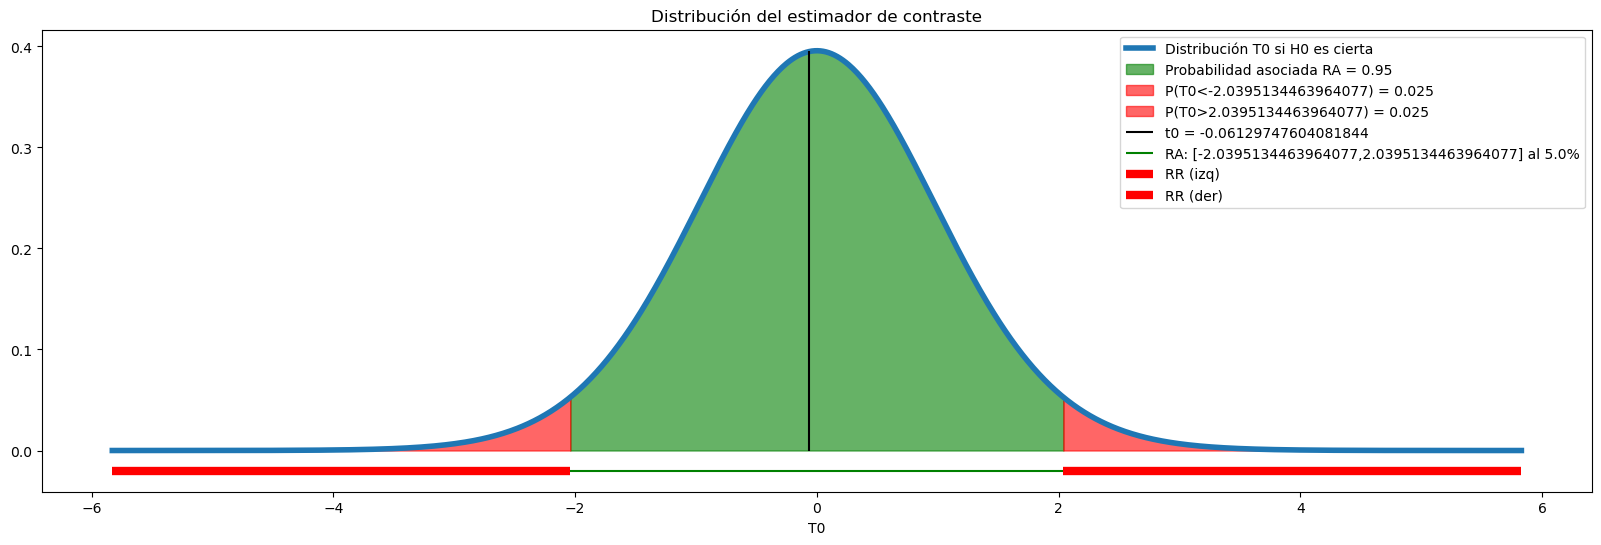

TtestResult(statistic=np.float64(-0.06129747604081844), pvalue=np.float64(0.9515158007658236), df=np.int64(31))

In [19]:
from scipy import stats

def contraste_media_two_sided(x, mu_0, alfa=0.05):

    alternativa="two-sided"
    # contraste de la media con varianza desconocida (viene de la chuleta de estadistica, cálculo directo)
    print(f'mu_0 es {mu_0}')
    print(f'H0: hipotesis a priori: la media en la fase eliminatoria es igual a la media en la fase de grupos')

    res = stats.ttest_1samp(x, popmean=mu_0, alternative=alternativa)
    print(f"n={len(x)} | media={np.mean(x):.2f} | mu_0={mu_0:.2f} | t0={res.statistic:.3f} | p-valor={res.pvalue:.3f}")

    t0 = res.statistic
    pvalor = res.pvalue

    print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')

    if pvalor < alfa:
        print(f"Se rechaza H0. Se verifica que pvalor = {pvalor} < alfa = {alfa} por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.")
    else:
        print(f"No se rechaza H0 (alfa={alfa}). Se verifica que pvalor = {pvalor} > alfa=  {alfa} por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.")


    # REPRESENTACIÓN GRÁFICA (BILATERAL) chuleta de primero
    n = len(x)
    x_media = np.mean(x)
    sx = np.std(x, ddof=1) # dividiendo por n-1

    t0 = (x_media - mu_0) / (sx/np.sqrt(n))

    # crea la distribución del estadístico de contraste
    gl = n -1 # grados de libertad
    T0 = stats.t(gl)

    # calculamos el pvalor (caso H1 BILATERAL)
    pvalor = 2 * (1 - T0.cdf(abs(t0)))

    # razonando con valores críticos
    # nivel de significación
    alfa = 0.05

    # determina los valores críticos que definen la región de rechazo (bilateral)
    t_crit_iz = T0.ppf(alfa/2)
    t_crit_de = T0.ppf(1-alfa/2)


    # puntos para representar la distribución y las regiones de aceptación y rechazo
    xmin = T0.ppf(0.000001)
    xmax = T0.ppf(1-0.000001)
    xs = np.linspace(xmin, xmax, 1000)
    xRA = np.linspace(t_crit_iz, t_crit_de, 1000)
    xRRiz = np.linspace(xmin, t_crit_iz, 1000)
    xRRde = np.linspace(t_crit_de, xmax, 1000)

    plt.figure(1, figsize=(20, 6))
    plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

    plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
    plt.fill_between( xRRiz, T0.pdf(xRRiz), color="red", alpha=0.6, label=f'P(T0<{t_crit_iz}) = {alfa/2}')
    plt.fill_between( xRRde, T0.pdf(xRRde), color="red", alpha=0.6, label=f'P(T0>{t_crit_de}) = {alfa/2}')

    plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')

    plt.hlines(-0.02, t_crit_iz, t_crit_de, color='green', label = f'RA: [{t_crit_iz},{t_crit_de}] al {alfa*100}%')
    plt.hlines(-0.02, xmin, t_crit_iz, color='red', linewidth = 6, label = f'RR (izq)')
    plt.hlines(-0.02, t_crit_de, xmax, color='red', linewidth = 6, label = f'RR (der)')

    plt.title('Distribución del estimador de contraste')
    plt.xlabel('T0')
    plt.legend()
    plt.show()

    return res



# tomar mu_0 como media de las tarjetas en fase de grupos
mu_0 = datos_partidos.loc[datos_partidos["ronda"] == "Group Stage", "tarjetas"].mean()

tarjetas_elim = datos_partidos.loc[datos_partidos["ronda"] != "Group Stage", "tarjetas"]
contraste_media_two_sided(tarjetas_elim, mu_0)

No se rechaza H0, así que no hay evidencia de que el criterio de tarjetas cambie al avanzar el torneo.

8) INTERVENCION ARBITRAL 

In [20]:
def filtrar_partidos(rondas=None, selecciones=None):
    #se toman los partidos de las rondas indicadas en los que juega alguna de las selecciones indicadas
    df = datos_partidos
    if rondas is not None:  #se toman las rondas indicadas y si no se indica ninguna, pues se toman todas las rondas
        df = df[df["ronda"].isin(rondas)]
    if selecciones is not None:     #lo mismo para las selecciones, ya sean locales o visitantes
        df = df[df["seleccion_local"].isin(selecciones) | df["seleccion_visitante"].isin(selecciones)]
    return df.copy()

def tabla_indice_arbitros(rondas=None, selecciones=None):
    # media del índice de intervencon, nº de partidos y máximo por árbitro

    #coger los partidos de la tonda y selecciones indicadas
    df = filtrar_partidos(rondas, selecciones)

    #calculamos las medidas quee queremos para cada arbitro
    resumen = df.groupby("arbitro_partido").agg(
        partidos=("index_partido", "count"),
        indice_medio=("indice_intervencion", "mean"),
        indice_max=("indice_intervencion", "max"),
        tarjetas_medias=("tarjetas", "mean"),
    )
    resumen = resumen.sort_values("indice_medio", ascending=False).round(2)

    return resumen

In [21]:
tabla_indice_arbitros().head(10)

,partidos,indice_medio,indice_max,tarjetas_medias
arbitro_partido,,,,
Cristián Garay,1,10.20,10.2,4.00
Alejandro José Hernández,1,8.40,8.4,7.00
Wilton Sampaio,3,6.73,13.4,4.00
Juan Gabriel Benítez,1,6.00,6.0,6.00
Slavko Vincic,4,5.90,12.2,4.00
Alireza Faghani,3,5.40,12.0,3.33
Iván Barton,4,5.30,6.2,3.75
João Pinheiro,3,5.13,8.8,3.33
Raphael Claus,1,5.00,5.0,3.00


In [22]:
tabla_indice_arbitros(rondas=["Semi-finals"], selecciones=["Argentina", "Spain"])

,partidos,indice_medio,indice_max,tarjetas_medias
arbitro_partido,,,,
Iván Barton,1,5.4,5.4,3.0
Ismail Elfath,1,3.6,3.6,3.0


In [23]:
def grafico_indice_arbitros(rondas=None, selecciones=None):
    df = filtrar_partidos(rondas, selecciones)
    resumen = tabla_indice_arbitros(rondas, selecciones)

    etiquetas = dict()
    for arbitro, fila in resumen.iterrows():        #iterrows nos permite ir iterando por filas del df de resumen de arbitros y crear las etiquetas
        etiquetas[arbitro] = f"{arbitro} ({fila['partidos']})"

    #guardamos las etiquetas de cada arbitro
    df["arbitro"] = df["arbitro_partido"].map(etiquetas)

    orden = []
    for a in resumen.index[::-1]:
        orden.append(etiquetas[a])  # recorremos el resumen al reves para dejar el más severo arriba y vamos guardabdo als etiqueras en orden para plotear despues en ese orden

    # permite pintar para cada arbitro los puntos corrwpondientes a los partidos que ha arbitrado, agrupandolos en color por ronda de competicion
    fig = px.strip(
        data_frame=df,
        x="indice_intervencion",
        y="arbitro",
        color="ronda",
        hover_name="etiqueta_partido",
        hover_data={"ronda": True, "tarjetas": True, "arbitro": False, "indice_intervencion": True},
        labels={"indice_intervencion": "Índice de Intervención Arbitral", "arbitro": "Árbitro (nº partidos)", "ronda": "Ronda", "tarjetas": "Tarjetas"},
        category_orders={"arbitro": orden, "ronda": ORDEN_RONDAS},
        title="Índice de Intervención Arbitral por árbitro",
        color_discrete_sequence= px.colors.qualitative.Plotly
        
    )
    fig.update_traces(marker=dict(size=9, opacity=0.8))

    ### esta funcion permite pintar las marcas de la media de inttervencion para cada arbitro (como duiamante en negro); no conociamos esta funcion de plotly, que hemos descubierto gracias a la IA para mejorar nuestra grafica
    fig.add_trace(
        go.Scatter(
            x=resumen["indice_medio"],
            y=[etiquetas[a] for a in resumen.index],
            mode="markers",
            name="Media del árbitro",
            marker=dict(symbol="diamond", size=11, color="black", line=dict(width=1, color="white")),
            hovertemplate="%{y}<br>Media: %{x:.2f}<extra></extra>",
        )
    )
    fig.update_layout(height=max(500, 26 * len(resumen) + 150), yaxis=dict(categoryorder="array", categoryarray=orden))
    return fig

In [24]:
grafico_indice_arbitros()

OBSERVACIONES
-hay gran disparidad entre el indice de intervencion de los arbitros: mientras algunos tienen un valor medio inferior a 1.5, otros llegan a más de 10!
-curioso, la mayoria de arbitros con un unico partido tienen un mayor índice de intervencion arbitral: es decir los que solo arbitraron un partidon intervinieron más... ¿quieren tener más protagonismo? ¿o les meten en la nevera por ser muy polémicos y ya no arbitran más (el árbitro cuyo primer partido fue muy intervencionista no vuelve a ser designado.)?

-OJO, si nos fijamos en los “outliers”: los 3 partidos con índice ≥12 son (en orden) #1 México–Sudáfrica, la final, #92 México–Inglaterra : resulta curioso que aprtidos tan señalados como el partido inaugural o la final sean en los que mas oapeticipaci´ñon arbitral hubo... ¿querían tenerlos controlados?

aplicamos un contraste para greater (unilateral) para ver si lo que hemos observado respecto a los árbitros con un solo aprtido es real, es decir, que participan más:

H0: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto;
 H1: es mayor al del resto.

mu_0 es 3.3847826086956525
H0: hipotesis a priori: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto; H1: es mayor.
n=12 | media=4.98 | mu_0=3.38 | t0=2.419 | p-valor=0.017
El valor observado del estadistico de contraste es 2.4191564701003587, con un p-valor asociado igual a 0.017028866131402823.
Se rechaza H0. Se verifica que pvalor = 0.017028866131402823 < alfa = 0.05 por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.


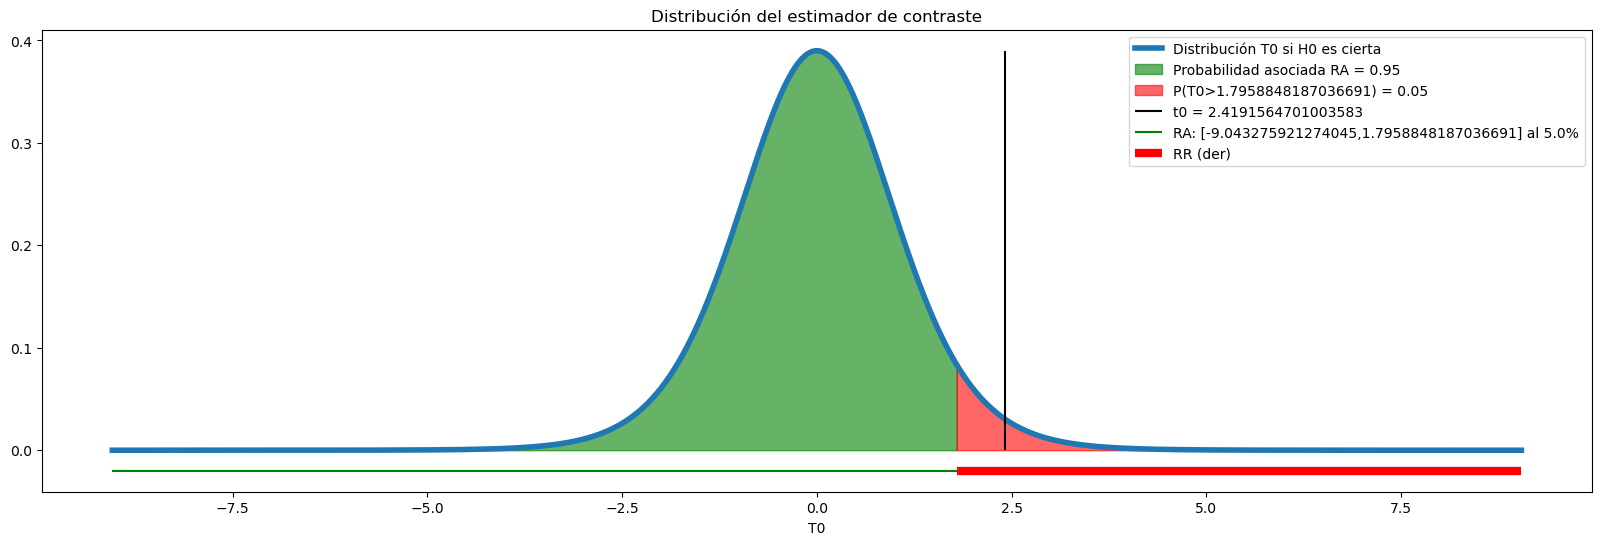

TtestResult(statistic=np.float64(2.4191564701003587), pvalue=np.float64(0.017028866131402823), df=np.int64(11))

In [25]:

def contraste_media_greater(x, mu_0, alfa=0.05):

    alternativa="greater"
    # contraste de la media con varianza desconocida (viene de la chuleta de estadistica, cálculo directo)
    print(f'mu_0 es {mu_0}')
    print(f'H0: hipotesis a priori: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto; H1: es mayor.')

    res = stats.ttest_1samp(x, popmean=mu_0, alternative=alternativa)
    print(f"n={len(x)} | media={np.mean(x):.2f} | mu_0={mu_0:.2f} | t0={res.statistic:.3f} | p-valor={res.pvalue:.3f}")

    t0 = res.statistic
    pvalor = res.pvalue

    print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')

    if pvalor < alfa:
        print(f"Se rechaza H0. Se verifica que pvalor = {pvalor} < alfa = {alfa} por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.")
    else:
        print(f"No se rechaza H0 (alfa={alfa}). Se verifica que pvalor = {pvalor} > alfa=  {alfa} por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.")


    # REPRESENTACIÓN GRÁFICA (BILATERAL) chuleta de primero
    n = len(x)
    x_media = np.mean(x)
    sx = np.std(x, ddof=1) # dividiendo por n-1

    t0 = (x_media - mu_0) / (sx/np.sqrt(n))

    # crea la distribución del estadístico de contraste
    gl = n -1 # grados de libertad
    T0 = stats.t(gl)

    # calculamos el pvalor (caso H1 UNILATERAL)
    pvalor = 1 - T0.cdf(t0)

    # razonando con valores críticos
    # nivel de significación
    alfa = 0.05

    # determina los valores críticos que definen la región de rechazo (unilateral superios)
    t_crit_de = T0.ppf(1-alfa)


    # puntos para representar la distribución y las regiones de aceptación y rechazo
    xmin = T0.ppf(0.000001)
    xmax = T0.ppf(1-0.000001)
    xs = np.linspace(xmin, xmax, 1000)
    xRA = np.linspace(xmin, t_crit_de, 1000)
    xRRde = np.linspace(t_crit_de, xmax, 1000)

    plt.figure(1, figsize=(20, 6))
    plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

    plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
    plt.fill_between( xRRde, T0.pdf(xRRde), color="red", alpha=0.6, label=f'P(T0>{t_crit_de}) = {alfa}')

    plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')

    plt.hlines(-0.02, xmin, t_crit_de, color='green', label = f'RA: [{xmin},{t_crit_de}] al {alfa*100}%')
    plt.hlines(-0.02, t_crit_de, xmax, color='red', linewidth = 6, label = f'RR (der)')

    plt.title('Distribución del estimador de contraste')
    plt.xlabel('T0')
    plt.legend()
    plt.show()

    return res


#primero atrobuirle a cada arbitro el numero de partidos que ha arbitrado en el mundial
n_partidos_arbitro = datos_partidos.groupby("arbitro_partido")["index_partido"].transform("count")

#tomo los arbitros  que solo han arbitrado un partido
indice_un_partido = datos_partidos.loc[n_partidos_arbitro == 1, "indice_intervencion"]

#mu_0 será la media del indice de intervencion de los arbitros que han arbitrado más de un partido y frente a ella oponemos los datos de los que solo han arbitrado uno
mu_0 = datos_partidos.loc[n_partidos_arbitro > 1, "indice_intervencion"].mean()

contraste_media_greater(indice_un_partido, mu_0)

CONCLUSIÓN DEL CONTRASTE:
Se rechaza H0 al 5%: los árbitros de un solo partido tienen un índice significativamente mayor de intervencion que los que han aritrado más de uno!

pero ojo:
n = 12 es pequeño, y el índice es algo asímetrico por lo que el resultado puede resultar ilutrativo pero no totalmente concluyente. Por lo que las posibles explicaciones de la nevera o de un ciuerto afán de protagonismo siguen válidas.

In [33]:
def severidad_arbitros_seleccion(seleccion, rondas=None):
    # árbitros que han dirigido partidos de la selección, con la media del índice de intervencion en esos partidos (y ordenamos de menos a más severo)
    df = filtrar_partidos(rondas, seleccion)
    resumen = df.groupby("arbitro_partido").agg(
        partidos=("index_partido", "count"),
        indice_medio=("indice_intervencion", "mean")
    )
    resumen = resumen.sort_values(["indice_medio", "partidos"], ascending=[True, False]).round(2)

    return resumen


def grafico_arbitros_seleccion(seleccion, rondas=None):

    #tomamos solo la seleccion y ronda que queremos y ordenamos segun intervengan los arbotros en ese partido
    df = filtrar_partidos(rondas, seleccion)
    df = df.sort_values("indice_intervencion")

    #creamos una etiqueta que contenga el nombre del arbitro del partido y cual es el partido en cuestion
    df["etiqueta"] = df["arbitro_partido"] + " – " + df["partido"]

    #con esta funcion lo que hacemos es asociar: si el indice es el máximo->es el mas severo; si el indice es igual al minimo -> meno severo y si no, intermedio
    minimo = df["indice_intervencion"].min()
    maximo = df["indice_intervencion"].max()

    def asignar_como_de_severo(row):
        if row["indice_intervencion"] == maximo:
            return "Más severo"
        elif row["indice_intervencion"] == minimo:
            return "Menos severo"
        return "Intermedio"


    
    df["severidad"] = df.apply(asignar_como_de_severo, axis=1)


    fig = px.bar(
        data_frame=df,
        x="indice_intervencion",
        y="etiqueta",
        orientation="h",
        color="severidad",
        hover_name="etiqueta_partido",
        hover_data={"ronda": True, "tarjetas": True, "etiqueta": False, "severidad": False},
        labels={"indice_intervencion": "Índice de Intervención Arbitral", "etiqueta": "Árbitro – partido", "ronda": "Ronda", "tarjetas": "Tarjetas", "severidad": ""},
        color_discrete_map={"Menos severo": "#2ecc71", "Más severo": "#e74c3c", "Intermedio": "#95a5a6"},   #asignamos los colores en funcion de la severidad
        title=f"Árbitros de los partidos de {seleccion} (de menos a más severo)",
    )
    fig.update_layout(yaxis=dict(categoryorder="array", categoryarray=df["etiqueta"].tolist(), automargin=True ))


    return fig


In [27]:
severidad_arbitros_seleccion(["Spain"])

,partidos,indice_medio
arbitro_partido,,
Adham Makhadmeh,1,2.0
Espen Eskås,2,2.2
Anthony Taylor,1,3.2
Szymon Marciniak,1,4.2
Michael Oliver,1,4.6
Iván Barton,1,5.4
Slavko Vincic,1,12.2


In [34]:
grafico_arbitros_seleccion(["Spain"])

In [29]:
## finalmente, si queremos determinar cuales son los arbitros que son más veces los más severos pàra una seleccion o los menos severos
## lo que hacemos es que para cada saleccion vamos a buscar el arbitro que fuera el más severo en sus partidos y el que menos
# y finalmente para cada uno de los arbitros en base a esa tabla sacamos cuales son los mñas sseveros para un mayor numero de seleccciones

def tabla_severidad_selecciones(rondas=None):
    # para cada selección buscamos el árbitro menos severo y el árbitro más severo (según la media del índice en sus partidos)

    #empezamos guardando las selecciones, todas sus apariciones en encuentros
    selecciones = []

    for seleccion in partidos["seleccion_local"]:
        if seleccion not in selecciones:
            selecciones.append(seleccion)

    for seleccion in partidos["seleccion_visitante"]:
        if seleccion not in selecciones:
            selecciones.append(seleccion)

    selecciones.sort()

    filas = []

    for seleccion in selecciones:
        s = severidad_arbitros_seleccion([seleccion], rondas) #recordemos que esta funcion devolvía un df (al que llamamos aqui s) con los arbitros de una seleccion ordenados de menos a más severo
        menos = s.iloc[0]   #corresponde a la fila del árbitro menos severo para la seleccion
        mas = s.iloc[-1]    #corresponde a la fila del árbitro MAS severo para la seleccion

        fila = {
            "seleccion": seleccion,
            "partidos": int(s["partidos"].sum()),       #cuantos partidos ha jugado la seleccion
            "arbitro_menos_severo": s.index[0],         #arbitro menos severo
            "indice_menos_severo": menos["indice_medio"],       #y su indice
            "arbitro_mas_severo": s.index[-1],      #arbitro mas severo
            "indice_mas_severo": mas["indice_medio"]        #y su indice
        }

        filas.append(fila)

    return pd.DataFrame(filas)

def coincidencias_arbitros(rondas=None):
    # ahora ya solo queda contar el numero de selecciones (de la trabla que avabamos de crear) para las cuales cada árbitro es el menos severo / el más severo
    tabla = tabla_severidad_selecciones(rondas)
    menos = tabla["arbitro_menos_severo"].value_counts().rename("veces_menos_severo")       #esto devuelve un dataframe en el que las llaves son lo snombres de los arbitros y los valores es el numero de veces que ese arbitro es el menos severo para una seleccion
    mas = tabla["arbitro_mas_severo"].value_counts().rename("veces_mas_severo")             #esto devuelve un dataframe en el que las llaves son lo snombres de los arbitros y los valores es el numero de veces que ese arbitro es el MAS severo para una seleccion
    tabla_coincidencias_arbitros =  pd.concat([menos, mas], axis=1)         #funtamos los dos df que hemos creado en uno solo para que cada arbitro tenga dos columnas que sean el numero de veces que ha sdo el menos y mas severo para una seleccion
    tabla_coincidencias_arbitros = tabla_coincidencias_arbitros.fillna(0).astype(int)       #porque sin el astype int nos deja los numeros de partidos arbitrados como float y queda más bonito int
    tabla_coincidencias_arbitros["partidos_arbitrados"] = tabla_coincidencias_arbitros.index.map(filtrar_partidos(rondas)["arbitro_partido"].value_counts())        # así añadimos el dato del numero de partidos arbitrados por cada arbitro a la tabla resumen
    tabla_coincidencias_arbitros = tabla_coincidencias_arbitros.sort_values(["veces_mas_severo", "veces_menos_severo"], ascending=False)        #y terminamos ordenando para que los mas severos queden arriba
    return tabla_coincidencias_arbitros


In [30]:
tabla_severidad_selecciones().head()

,seleccion,partidos,arbitro_menos_severo,indice_menos_severo,arbitro_mas_severo,indice_mas_severo
0,Algeria,4,Szymon Marciniak,0.6,Slavko Vincic,2.6
1,Argentina,8,Szymon Marciniak,0.6,Slavko Vincic,12.2
2,Australia,4,Drew Fischer,0.4,Alejandro José Hernández,8.4
3,Austria,4,Espen Eskås,1.6,Wilton Sampaio,4.4
4,Belgium,6,Adham Makhadmeh,3.0,Raphael Claus,5.0


In [31]:
coincidencias_arbitros().head(10)

,veces_menos_severo,veces_mas_severo,partidos_arbitrados
Slavko Vincic,1,4,4
Iván Barton,0,4,4
Glenn Nyberg,1,3,3
Wilton Sampaio,0,3,3
Ismail Elfath,0,3,4
Maurizio Mariani,3,2,3
István Kovács,2,2,3
Alireza Faghani,1,2,3
Anthony Taylor,1,2,3
Alejandro José Hernández,0,2,1


OBSERVACIONES
-Vincic y Barton son los más severos en 4 selecciones cada uno, y solo han arbitrado 4 partidos!. PERO OJO, aunque podría parecer que esto sea importante, no se puede tomar como muy significatio tampoco, pues un mismo partido cuenta para dos selecciones, por ejemplo, la final con Vincic (12,2) lo hace “más severo” de España y de Argentina a la vez, llevandolo al principio de la tabla. por otro lado una selección con 3 partidos de grupo solo tiene 3 árbitros y “el más severo” es simplemente el máximo de 3, lo cual tampoco puede llegar a indicar que sea un arbitro más exigente... Es decir, en conclusion, no se puede deciir que haya árbitros que sean “sistemáticamente duros” con selecciones distintas.
-en cuanto al índice, en el fondo consiste en medir el número de tarjetas que saca un árbitro, si son muy tarjeteros o no, pues la influencia de los goles no tiene prácticamente peso, y revisiones de var no hubo muchas (15 en todo el mundial). La influencia de un árbitro va mucho más haya pues de simplememte las tarjetas o las revisiones de var que haga, sino que pasa por otros aspectos del partido: faltas señaladas o no etc que pueden tener más influencia en el partido sinq ue sea posible señalarlo en las bases de datos de las que disponemos.

extra cuando haya acabado todo pensar que más analisis se pueden poder interesantes basandonos en las graficas vistas

ver algo con pvalores 

y si se pueden añadir cosas que se me ocurran 